# AT2 - Rede Neural MLP para previsão de cancelamento de clientes (Churn)

## 1. Contexto do Problema e Dicionário de Dados

**Origem:** dataset *Telco Customer Churn*, disponível no Kaggle em <https://www.kaggle.com/datasets/blastchar/telco-customer-churn> (arquivo `WA_Fn-UseC_-Telco-Customer-Churn.csv`, salvo neste repositório como `data/dataset.csv`). Cada linha representa um cliente de uma operadora de telecomunicações (telefonia e internet).

**Objetivo de negócio:** prever se um cliente irá cancelar o serviço (*churn*). Reter um cliente costuma custar bem menos do que conquistar um novo, então identificar com antecedência quem tem maior risco de saída permite ações de retenção direcionadas (ofertas, contato proativo, migração de contrato).

**Tipo de problema:** classificação binária (`Cancelou` x `Permaneceu`).

| Coluna | Tipo | Significado prático |
|---|---|---|
| `gender` | categórica | Gênero do cliente (`Female`, `Male`) |
| `SeniorCitizen` | binária (0/1) | Indica se o cliente é idoso (1) ou não (0) |
| `Partner` | categórica | Possui parceiro(a) (`Yes`/`No`) |
| `Dependents` | categórica | Possui dependentes (`Yes`/`No`) |
| `tenure` | numérica (int) | Meses de permanência como cliente |
| `PhoneService` | categórica | Possui telefonia (`Yes`/`No`) |
| `InternetService` | categórica | Tipo de internet (`DSL`, `Fiber optic`, `No`) |
| `OnlineSecurity` | categórica | Serviço de segurança online (`Yes`, `No`, `No internet service`) |
| `TechSupport` | categórica | Suporte técnico (`Yes`, `No`, `No internet service`) |
| `Contract` | categórica | Tipo de contrato (`Month-to-month`, `One year`, `Two year`) |
| `PaperlessBilling` | categórica | Fatura digital (`Yes`/`No`) |
| `PaymentMethod` | categórica | Forma de pagamento (`Electronic check`, `Mailed check`, `Bank transfer (automatic)`, `Credit card (automatic)`) |
| `MonthlyCharges` | numérica (float) | Valor cobrado mensalmente (US$) |
| `TotalCharges` | numérica (float) | Valor total cobrado ao longo do relacionamento (US$) |
| `Churn` | **alvo** | Cliente cancelou o serviço (`Yes`) ou permaneceu (`No`) |

A coluna `customerID` é apenas um identificador e é descartada. As demais colunas de serviços adicionais do dataset original foram deixadas de fora para manter o contrato da API enxuto.

In [1]:
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    matthews_corrcoef,
)
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

SEED = 77
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = ROOT / "data" / "dataset.csv"
MODEL_PATH = ROOT / "models" / "pipeline_rede_neural.joblib"

## 2. Análise Exploratória Resumida

In [2]:
df = pd.read_csv(DATA_PATH)
print("Dimensões (linhas, colunas):", df.shape)
df.head()

Dimensões (linhas, colunas): (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("Tipos de dados:")
print(df.dtypes, end="\n\n")
print("Valores ausentes por coluna:")
print(df.isna().sum()[lambda s: s > 0])
print("\nLinhas com TotalCharges ausente:")
print(df.loc[df["TotalCharges"].isna(), ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]].head())

Tipos de dados:
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
dtype: object

Valores ausentes por coluna:
TotalCharges    11
dtype: int64

Linhas com TotalCharges ausente:
      tenure  MonthlyCharges  TotalCharges Churn
488        0           52.55           NaN    No
753        0           20.25           NaN    No
936        0           80.85           NaN    No
1082       0           25.75           NaN    No
1340       0           56.05           Na

`TotalCharges` vem como texto porque 11 clientes novos (`tenure = 0`) possuem o campo em branco. A conversão numérica os transforma em `NaN`, que será tratado por um `SimpleImputer` dentro do próprio pipeline, evitando vazamento de informação do conjunto de teste.

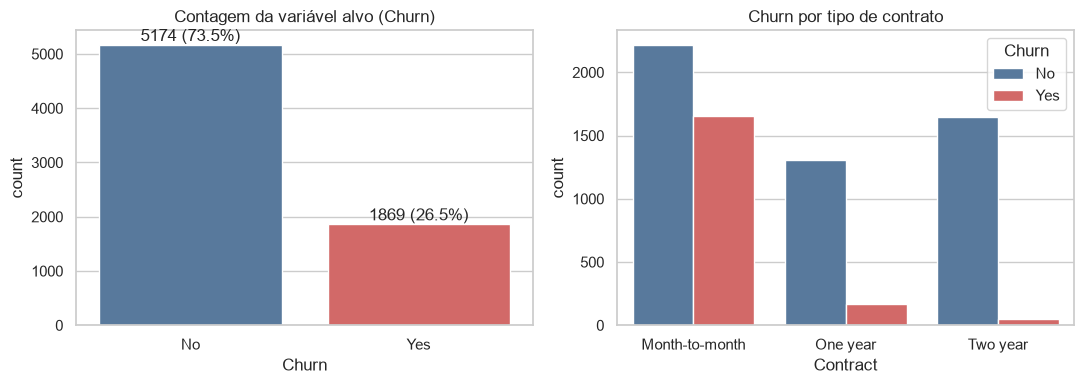

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

contagem = df["Churn"].value_counts()
sns.countplot(data=df, x="Churn", order=["No", "Yes"], ax=axes[0], palette=["#4c78a8", "#e45756"])
axes[0].set_title("Contagem da variável alvo (Churn)")
for i, classe in enumerate(["No", "Yes"]):
    axes[0].text(i, contagem[classe], f"{contagem[classe]} ({contagem[classe] / len(df):.1%})", ha="center", va="bottom")

sns.countplot(data=df, x="Contract", hue="Churn", hue_order=["No", "Yes"], ax=axes[1], palette=["#4c78a8", "#e45756"])
axes[1].set_title("Churn por tipo de contrato")

plt.tight_layout()
plt.show()

O alvo é **desbalanceado** (cerca de 73% permanecem e 27% cancelam), por isso a acurácia sozinha é enganosa e o relatório por classe e o MCC serão essenciais na avaliação. A divisão treino/teste será estratificada.

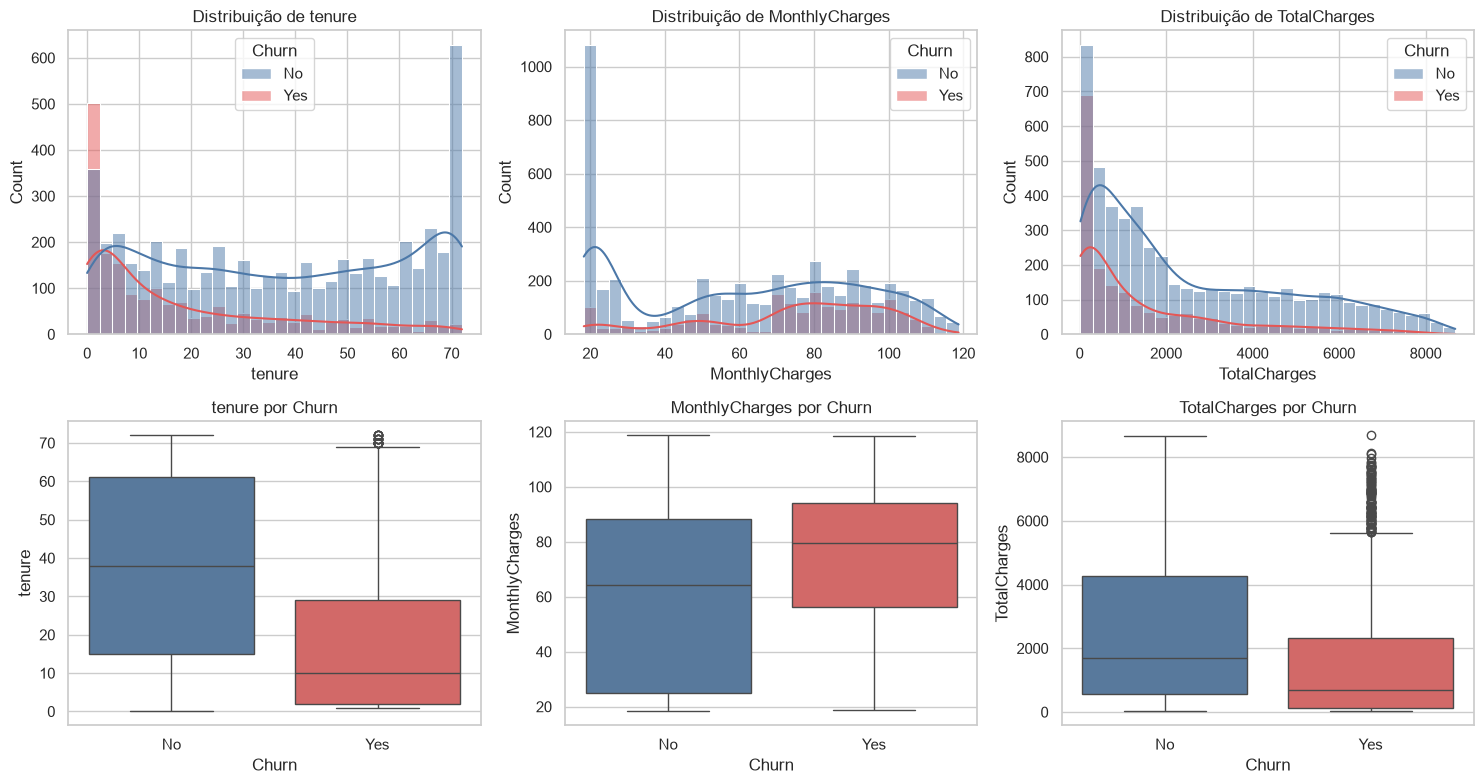

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, col in zip(axes[0], ["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.histplot(data=df, x=col, hue="Churn", hue_order=["No", "Yes"], bins=30, kde=True, ax=ax, palette=["#4c78a8", "#e45756"])
    ax.set_title(f"Distribuição de {col}")

for ax, col in zip(axes[1], ["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.boxplot(data=df, x="Churn", y=col, order=["No", "Yes"], ax=ax, palette=["#4c78a8", "#e45756"])
    ax.set_title(f"{col} por Churn")

plt.tight_layout()
plt.show()

Clientes que cancelam tendem a ter **menor tempo de casa** (`tenure`) e **mensalidade mais alta**, o que justifica o uso dessas variáveis como preditoras.

## 3. Construção do Pipeline Scikit-Learn

In [6]:
COLUNAS_NUMERICAS = ["tenure", "MonthlyCharges", "TotalCharges"]
COLUNAS_CATEGORICAS = [
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents",
    "PhoneService",
    "InternetService",
    "OnlineSecurity",
    "TechSupport",
    "Contract",
    "PaperlessBilling",
    "PaymentMethod",
]

X = df[COLUNAS_NUMERICAS + COLUNAS_CATEGORICAS].copy()
X["SeniorCitizen"] = X["SeniorCitizen"].map({0: "No", 1: "Yes"})
y = df["Churn"].map({"Yes": "Cancelou", "No": "Permaneceu"})

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)
print("Treino:", X_treino.shape, "| Teste:", X_teste.shape)
print(y_treino.value_counts(normalize=True).round(3).to_dict())
print(y_teste.value_counts(normalize=True).round(3).to_dict())

Treino: (5634, 14) | Teste: (1409, 14)
{'Permaneceu': 0.735, 'Cancelou': 0.265}
{'Permaneceu': 0.735, 'Cancelou': 0.265}


In [7]:
preprocessador = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline([
                ("imputador", SimpleImputer(strategy="median")),
                ("escalonador", StandardScaler()),
            ]),
            COLUNAS_NUMERICAS,
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            COLUNAS_CATEGORICAS,
        ),
    ]
)

mlp = MLPClassifier(
    hidden_layer_sizes=(128, 64, 32),
    activation="relu",
    solver="adam",
    alpha=1e-3,
    learning_rate_init=1e-3,
    max_iter=500,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=15,
    random_state=SEED,
)

pipeline = Pipeline([("preprocessamento", preprocessador), ("modelo", mlp)])
pipeline.fit(X_treino, y_treino)

print("Iterações realizadas:", pipeline.named_steps["modelo"].n_iter_)
print("Classes:", list(pipeline.classes_))

Iterações realizadas: 20
Classes: [np.str_('Cancelou'), np.str_('Permaneceu')]


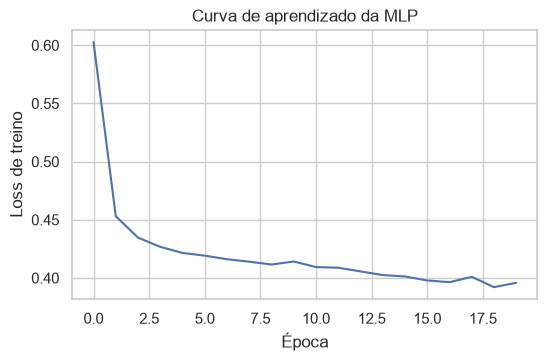

In [8]:
curva = pipeline.named_steps["modelo"].loss_curve_
plt.figure(figsize=(6, 3.5))
plt.plot(curva)
plt.xlabel("Época")
plt.ylabel("Loss de treino")
plt.title("Curva de aprendizado da MLP")
plt.show()

## 4. Avaliação do Modelo

In [9]:
y_previsto = pipeline.predict(X_teste)

acuracia = accuracy_score(y_teste, y_previsto)
mcc = matthews_corrcoef(y_teste, y_previsto)

print(f"Acurácia global no teste: {acuracia:.4f}")
print(f"Coeficiente de Matthews (MCC): {mcc:.4f}\n")
print(classification_report(y_teste, y_previsto, digits=3))

Acurácia global no teste: 0.8126
Coeficiente de Matthews (MCC): 0.4897

              precision    recall  f1-score   support

    Cancelou      0.688     0.537     0.604       374
  Permaneceu      0.845     0.912     0.877      1035

    accuracy                          0.813      1409
   macro avg      0.767     0.725     0.740      1409
weighted avg      0.804     0.813     0.805      1409



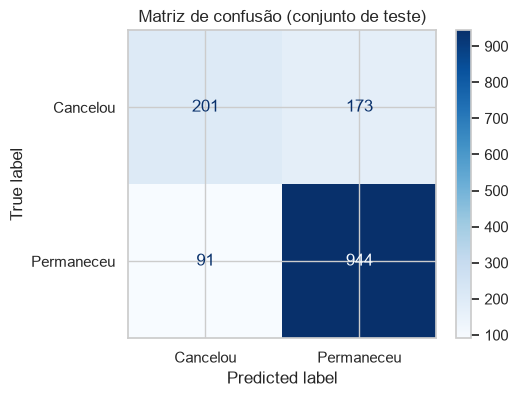

In [10]:
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_teste, y_previsto, labels=list(pipeline.classes_), cmap="Blues", ax=ax
)
ax.set_title("Matriz de confusão (conjunto de teste)")
plt.show()

**Leitura dos resultados:** a diagonal principal traz os acertos. Os **falsos negativos** (cliente que cancelou e o modelo previu `Permaneceu`) são o erro mais custoso para o negócio, pois representam oportunidades de retenção perdidas. Já os **falsos positivos** (previu cancelamento, mas o cliente ficou) geram o custo de uma ação de retenção desnecessária. Por causa do desbalanceamento, o recall da classe `Cancelou` e o MCC dão uma visão mais honesta do que a acurácia isolada.

## 5. Exportação do Modelo Treinado

In [11]:
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(pipeline, MODEL_PATH)

recarregado = joblib.load(MODEL_PATH)
assert (recarregado.predict(X_teste) == y_previsto).all()
print("Pipeline salvo em:", MODEL_PATH.relative_to(ROOT))
print("Tamanho (KB):", round(MODEL_PATH.stat().st_size / 1024, 1))

Pipeline salvo em: models\pipeline_rede_neural.joblib
Tamanho (KB): 353.1


O arquivo `.joblib` contém o `Pipeline` completo (imputação, normalização, One-Hot e MLP). A API recebe dados brutos e aplica exatamente as mesmas transformações aprendidas no treino.